<div align="center">
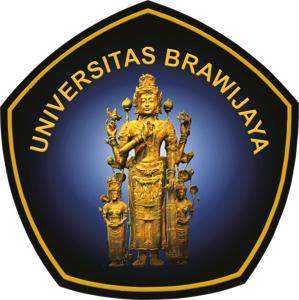

# PENGENALAN BILANGAN TULISAN TANGAN

## HITUNGIN

**CNN · BiGRU · CTC · ONNX**

Notebook eksperimen pembelajaran mesin · LOGICODIX 2026  
Universitas Brawijaya · Malang · 2026

**Penyusun: Tim HITUNGIN**

</div>

---

**Alur CRISP-DM:** Pemahaman Bisnis → Pemahaman Data → Persiapan Data → Pemodelan → Evaluasi → Deployment.

**Cara menjalankan:** pilih runtime GPU T4 di Google Colab, kemudian jalankan sel secara berurutan.
Profil `poc` adalah eksperimen terbatas yang benar-benar melatih dan mengevaluasi model;
ubah `HITUNGIN_PROFILE=full` sebelum sel konfigurasi untuk eksperimen lebih panjang.
Hasil pengenalan selalu dikonfirmasi pengguna sebelum dinilai dengan aturan matematika.
Logo merupakan identitas cover, bukan tanda pengesahan universitas.


## Petunjuk reproduksi

Notebook ini mandiri: mengunduh data publik bila belum tersedia, menetapkan seed,
mencatat versi paket, dan menyimpan artefak di `artifacts/`. Direktori runtime Colab
bersifat sementara. Unduh ZIP artefak di akhir sebelum menutup sesi.
Nilai metrik tidak diisi manual; semuanya dihitung oleh sel evaluasi.


In [ ]:
# @title Instalasi dependensi
%pip -q install requests pandas numpy matplotlib scikit-learn pillow onnx==1.19.1 onnxruntime==1.23.2


In [ ]:
# @title Konfigurasi eksperimen dan utilitas

import os, sys, json, random, time, copy, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path('/content/hitungin') if Path('/content').exists() else Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
ROOT.mkdir(parents=True, exist_ok=True)
PROFILE = os.environ.get('HITUNGIN_PROFILE', 'poc')
assert PROFILE in {'poc', 'full'}
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
print({'profil': PROFILE, 'perangkat': str(DEVICE), 'python': platform.python_version(),
       'torch': torch.__version__, 'root': str(ROOT)})
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str) + '\n')

def save_environment(folder):
    import importlib.metadata as metadata
    names = ['torch', 'numpy', 'pandas', 'scikit-learn', 'onnx', 'onnxruntime',
             'transformers', 'accelerate', 'jiwer', 'soundfile']
    versions = {}
    for name in names:
        try: versions[name] = metadata.version(name)
        except metadata.PackageNotFoundError: pass
    save_json(folder / 'environment.json', versions)

def index_artifacts(folder):
    records = []
    for path in sorted(folder.rglob('*')):
        if path.is_file() and path.name != 'manifest.json':
            sha = hashlib.sha256()
            with path.open('rb') as handle:
                for block in iter(lambda: handle.read(1024*1024), b''): sha.update(block)
            records.append({'file': str(path.relative_to(folder)), 'bytes': path.stat().st_size,
                            'sha256': sha.hexdigest()})
    save_json(folder / 'manifest.json', records)
    return pd.DataFrame(records)


{'profil': 'poc', 'perangkat': 'cuda', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'root': '/content/hitungin'}
GPU: Tesla T4


In [ ]:
# @title Pengunduh sumber publik (dapat dijalankan ulang)
import concurrent.futures
import hashlib
import io
import json
import subprocess
import sys
import time
import zipfile
from pathlib import Path
import requests
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
def download(url, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        partial = path.with_suffix(path.suffix + ".part")
        for attempt in range(3):
            try:
                offset = partial.stat().st_size if partial.exists() else 0
                headers = {"Range": f"bytes={offset}-"} if offset else {}
                with requests.get(url, headers=headers, stream=True, timeout=(30, 120)) as response:
                    response.raise_for_status()
                    append = offset and response.status_code == 206
                    if append:
                        assert response.headers.get("Content-Range", "").startswith(f"bytes {offset}-"), "Invalid resume response"
                    with partial.open("ab" if append else "wb") as output:
                        for chunk in response.iter_content(1024 * 1024):
                            output.write(chunk)
                partial.replace(path)
                break
            except requests.RequestException:
                if attempt == 2:
                    raise
                time.sleep(2)
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return {"url": url, "path": str(path.relative_to(ROOT)),
            "bytes": path.stat().st_size, "sha256": digest.hexdigest()}

def mnist():
    names = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
             "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
    return {"dataset": "mnist", "downloads": [
        download(f"https://ossci-datasets.s3.amazonaws.com/mnist/{name}", DATA / "raw/mnist" / name)
        for name in names]}

class RemoteZipReader(io.RawIOBase):
    """Read selected official ZIP members via HTTP ranges, without the full ZIP."""
    def __init__(self, url):
        self.url = url
        self.session = requests.Session()
        response = self.session.get(url, headers={"Range": "bytes=0-0"}, timeout=30)
        response.raise_for_status()
        assert response.status_code == 206, "Source must support range requests"
        self.size = int(response.headers["Content-Range"].split("/")[-1])
        self.position = 0

    def seek(self, offset, whence=0):
        self.position = offset if whence == 0 else (self.position if whence == 1 else self.size) + offset
        return self.position

    def tell(self):
        return self.position

    def seekable(self):
        return True

    def read(self, size=-1):
        if size < 0:
            size = self.size - self.position
        size = min(size, self.size - self.position)
        if size <= 0:
            return b""
        start = self.position
        end = start + size - 1
        response = self.session.get(self.url, headers={"Range": f"bytes={start}-{end}"}, timeout=(30, 120))
        response.raise_for_status()
        assert response.status_code == 206, "Range request not honored"
        content = response.content
        assert len(content) == size, "Incomplete range response"
        self.position += size
        return content

def emnist():
    url = "https://biometrics.nist.gov/cs_links/EMNIST/gzip.zip"
    destination = DATA / "raw/emnist"
    destination.mkdir(parents=True, exist_ok=True)
    files = []
    with zipfile.ZipFile(RemoteZipReader(url)) as source:
        for member in source.infolist():
            if not Path(member.filename).name.startswith("emnist-digits-"):
                continue
            path = destination / Path(member.filename).name
            if not path.exists():
                content = source.read(member)  # ZipFile verifies each member's CRC.
                partial = path.with_suffix(path.suffix + ".part")
                partial.write_bytes(content)
                partial.replace(path)
            files.append({"url": url, "zip_member": member.filename,
                          "path": str(path.relative_to(ROOT)), "bytes": path.stat().st_size,
                          "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
    return {"dataset": "emnist-digits", "method": "Official ZIP members via HTTP ranges", "downloads": files}


# 1. Pemahaman Bisnis

**Tujuan:** siswa menulis satu bilangan utuh, misalnya 7, 35, atau 100, pada
kanvas. Model menghasilkan string digit tanpa mewajibkan kotak per karakter.
Kandidat dibacakan/ditampilkan dan dikonfirmasi sebelum dinilai.

**Ruang lingkup PoC:** satu baris horizontal, 1–3 digit, bilangan jawaban 0–100.
Model dapat membaca string lain, tetapi aturan produk menolak nilai di luar
rentang. Nol di depan dipertahankan selama OCR dan dinormalisasi hanya setelah
konfirmasi. Ekspresi matematika, pecahan, dan tulisan bebas bukan target.

| Keputusan | Alasan |
|---|---|
| CNN + BiGRU + CTC | Mengenali urutan digit tanpa segmentasi karakter manual |
| Data sintetis dari digit publik | Tidak membutuhkan pengumpulan data baru |
| Exact match dan character error rate | Menilai bilangan utuh, bukan hanya digit terpisah |
| Evaluasi sintetis terpisah | Tidak menyatakan akurasi pada tulisan anak atau kanvas nyata |
| Sasaran awal | Exact match ≥95% pada evaluasi sintetis, kemudian uji kanvas |


In [ ]:
# @title Parameter eksperimen
import gzip, struct
from PIL import Image, ImageOps, ImageFilter
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import Dataset, DataLoader
ART=ROOT/'artifacts/tulisan_tangan'; ART.mkdir(parents=True,exist_ok=True)
CONFIG={'seed':SEED,'height':32,'width':96,'max_digits':3,'blank_id':10,
        'train_sequences':100000 if PROFILE=='full' else 20000,
        'val_sequences':3000 if PROFILE=='full' else 1000,
        'test_sequences':5000 if PROFILE=='full' else 1000,
        'epochs':30 if PROFILE=='full' else 20,'batch_size':128,'lr':0.001}
display(pd.Series(CONFIG))


,0
seed,42.000
height,32.000
width,96.000
max_digits,3.000
blank_id,10.000
train_sequences,20000.000
val_sequences,1000.000
test_sequences,1000.000
epochs,20.000
batch_size,128.000


# 2. Pemahaman Data

[MNIST](https://www.tensorflow.org/datasets/catalog/mnist) menyediakan digit
terisolasi; [EMNIST Digits dari NIST](https://www.nist.gov/itl/products-and-services/emnist-dataset)
menambah variasi penulis. Keduanya bukan dataset bilangan multi-digit pada kanvas.
Kita membangun urutan sintetis dari citra digit tersebut.

MNIST dan EMNIST memiliki hubungan sumber, jadi gabungan split resmi tidak boleh
langsung dianggap bebas kebocoran. Notebook mengaudit duplikasi piksel lintas
partisi setelah orientasi EMNIST diperbaiki. Audit ini belum menjamin pemisahan
penulis atau menghapus semua contoh yang hampir sama.


,sumber,jumlah
0,MNIST train,60000
1,MNIST test,10000
2,EMNIST train,240000
3,EMNIST test,40000


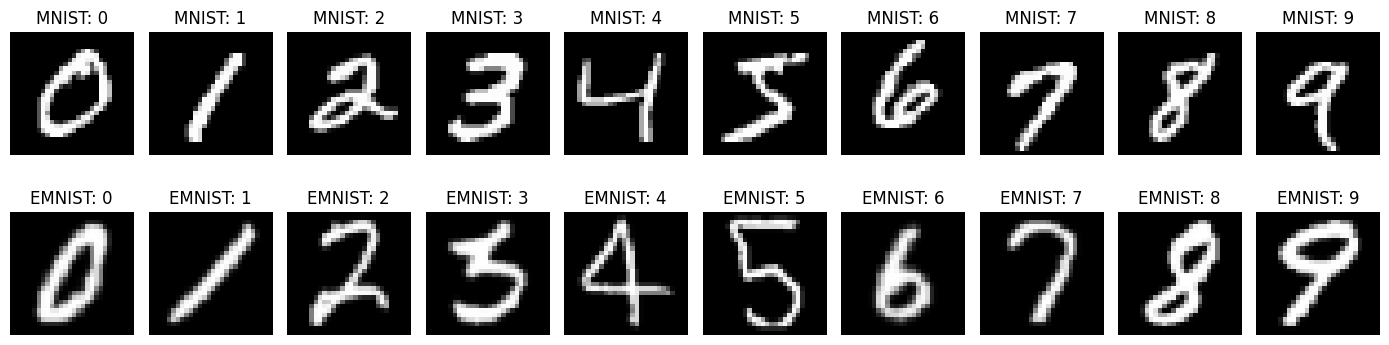

In [ ]:
# @title Unduh hanya berkas digit dan baca format IDX
if not (DATA/'raw/mnist/train-images-idx3-ubyte.gz').exists(): print(mnist())
if not (DATA/'raw/emnist/emnist-digits-train-images-idx3-ubyte.gz').exists(): print(emnist())

def read_idx(path):
    with gzip.open(path,'rb') as handle:
        zero,dtype,ndim=struct.unpack('>HBB',handle.read(4))
        assert zero==0 and dtype==8
        shape=struct.unpack('>'+'I'*ndim,handle.read(4*ndim))
        values=np.frombuffer(handle.read(),dtype=np.uint8).reshape(shape).copy()
    return values

def load_digits(kind, split):
    if kind=='mnist':
        prefix='train' if split=='train' else 't10k'
        folder=DATA/'raw/mnist'
        images=read_idx(folder/f'{prefix}-images-idx3-ubyte.gz')
        labels=read_idx(folder/f'{prefix}-labels-idx1-ubyte.gz')
    else:
        folder=DATA/'raw/emnist'
        images=read_idx(folder/f'emnist-digits-{split}-images-idx3-ubyte.gz').transpose(0,2,1).copy()
        labels=read_idx(folder/f'emnist-digits-{split}-labels-idx1-ubyte.gz')
    return images,labels

mi,my=load_digits('mnist','train'); ei,ey=load_digits('emnist','train')
mt,mty=load_digits('mnist','test'); et,ety=load_digits('emnist','test')
display(pd.DataFrame({'sumber':['MNIST train','MNIST test','EMNIST train','EMNIST test'],
                      'jumlah':[len(mi),len(mt),len(ei),len(et)]}))
fig,axes=plt.subplots(2,10,figsize=(14,4))
for digit in range(10):
    for row,(images,labels,name) in enumerate([(mi,my,'MNIST'),(ei,ey,'EMNIST')]):
        axes[row,digit].imshow(images[np.flatnonzero(labels==digit)[0]],cmap='gray')
        axes[row,digit].set_title(f'{name}: {digit}');axes[row,digit].axis('off')
plt.tight_layout();plt.show()


# 3. Persiapan Data

Urutan: perbaiki orientasi → pisahkan sumber digit → hapus duplikasi lintas
partisi → buat urutan sintetis **di dalam masing-masing partisi**. Satu citra
sumber tidak boleh dipakai pada training dan evaluasi, walaupun bilangan hasil
sintesis berbeda. Contoh kalibrasi dan evaluasi dibangkitkan dengan seed tetap.

Sintesis memakai crop tinta, skala/aspect ratio bervariasi, rotasi ringan,
variasi ketebalan, jarak, dan sedikit tumpang tindih. Ini memperluas variasi
sintetis tetapi tidak menggantikan data touchscreen nyata.


In [ ]:
# @title Audit duplikasi piksel dan bangun pool yang terpisah
def image_hashes(images):
    return np.array([hashlib.blake2b(img.tobytes(),digest_size=16).hexdigest() for img in images])
train_images=np.concatenate([mi,ei]); train_labels=np.concatenate([my,ey])
test_images=np.concatenate([mt,et]); test_labels=np.concatenate([mty,ety])
test_hash=image_hashes(test_images)
_,unique_test=np.unique(test_hash,return_index=True)
test_images,test_labels,test_hash=test_images[unique_test],test_labels[unique_test],test_hash[unique_test]
train_hash=image_hashes(train_images)
keep=~np.isin(train_hash,test_hash)
removed=int((~keep).sum()); train_images,train_labels,train_hash=train_images[keep],train_labels[keep],train_hash[keep]
_,unique_train=np.unique(train_hash,return_index=True)
train_images,train_labels=train_images[unique_train],train_labels[unique_train]
fit_idx,val_idx=train_test_split(np.arange(len(train_images)),test_size=0.1,stratify=train_labels,random_state=SEED)
pools={'train':(train_images[fit_idx],train_labels[fit_idx]),
       'val':(train_images[val_idx],train_labels[val_idx]),'test':(test_images,test_labels)}
split_info={key:len(value[0]) for key,value in pools.items()}
split_info.update(exact_train_test_duplicates_removed=removed,writer_independent=False)
save_json(ART/'split.json',split_info);display(pd.Series(split_info))
del mi,my,ei,ey,mt,mty,et,ety,train_images,train_labels,train_hash,test_hash


,0
train,270000
val,30000
test,50000
exact_train_test_duplicates_removed,0
writer_independent,False


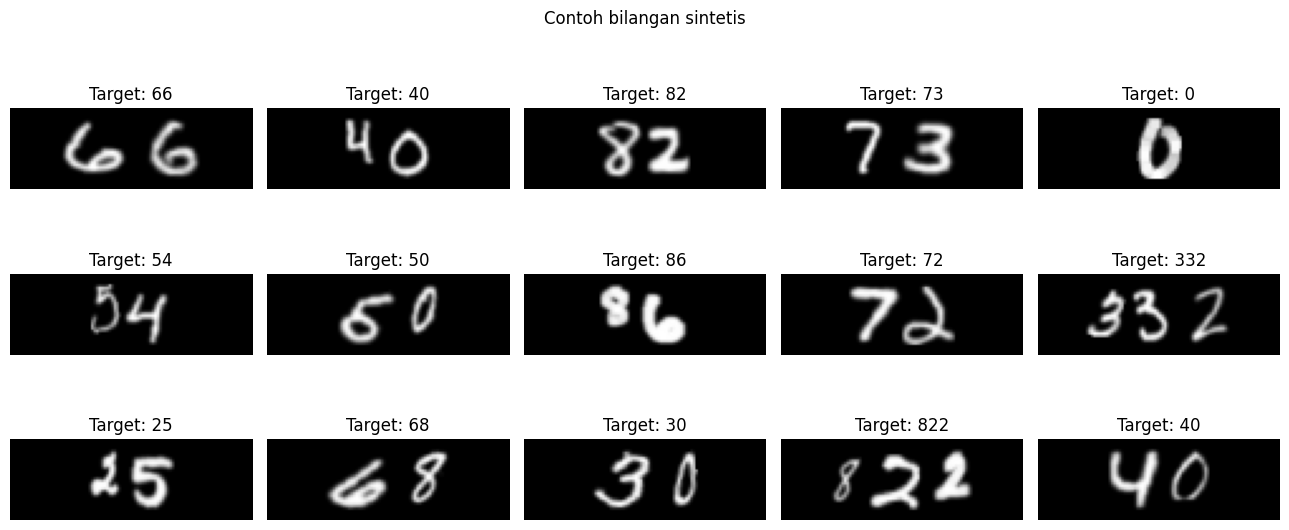

In [ ]:
# @title Bangkitkan bilangan utuh dengan variasi gaya digit publik
def preprocess_canvas(image, height=32, width=96):
    """Input grayscale: tinta putih di atas latar hitam, sama dengan renderer."""
    image=image.convert('L'); box=image.getbbox()
    if box is None: return np.zeros((1,height,width),dtype=np.float32)
    cropped=image.crop(box)
    ratio=min((width-8)/cropped.width,(height-8)/cropped.height)
    resized=cropped.resize((max(1,round(cropped.width*ratio)),max(1,round(cropped.height*ratio))),Image.Resampling.BILINEAR)
    out=Image.new('L',(width,height),0)
    out.paste(resized,((width-resized.width)//2,(height-resized.height)//2))
    return np.asarray(out,dtype=np.float32)[None]/255.0

class SyntheticNumbers(Dataset):
    def __init__(self, images,labels,size,seed,augment=False,targets=None):
        self.images,self.labels,self.size,self.seed,self.augment=images,labels,size,seed,augment
        self.by_digit={d:np.flatnonzero(labels==d) for d in range(10)}
        self.epoch=0;self.targets=targets
    def __len__(self): return self.size
    def __getitem__(self,index):
        rng=np.random.default_rng(self.seed+index+self.epoch*1000003)
        if self.targets is not None: text=self.targets[index%len(self.targets)]
        elif rng.random()<0.8: text=str(rng.integers(0,101))
        else: text=''.join(str(v) for v in rng.integers(0,10,size=rng.integers(1,4)))
        glyphs=[]
        for char in text:
            img=Image.fromarray(self.images[rng.choice(self.by_digit[int(char)])])
            box=img.getbbox();img=img.crop(box) if box else img
            new_height=int(rng.integers(20,29));new_width=max(4,int(img.width*new_height/img.height*rng.uniform(0.8,1.15)))
            img=img.resize((new_width,new_height),Image.Resampling.BILINEAR)
            if self.augment:
                img=img.rotate(float(rng.uniform(-9,9)),resample=Image.Resampling.BILINEAR,expand=True)
                if rng.random()<0.15:img=img.filter(ImageFilter.MaxFilter(3))
            glyphs.append(img)
        gaps=rng.integers(-1 if self.augment else 0,7,size=max(0,len(glyphs)-1))
        canvas=Image.new('L',(sum(i.width for i in glyphs)+int(gaps.sum())+12,40),0)
        x=6
        for i,glyph in enumerate(glyphs):
            layer=Image.new('L',canvas.size,0);layer.paste(glyph,(x,int(rng.integers(3,9))))
            canvas=Image.fromarray(np.maximum(np.asarray(canvas),np.asarray(layer)))
            x+=glyph.width+(int(gaps[i]) if i<len(gaps) else 0)
        return torch.from_numpy(preprocess_canvas(canvas)),torch.tensor([int(c) for c in text],dtype=torch.long),text

def collate_numbers(batch):
    images,targets,texts=zip(*batch)
    return torch.stack(images),torch.cat(targets),torch.tensor([len(t) for t in targets]),list(texts)

train_ds=SyntheticNumbers(*pools['train'],CONFIG['train_sequences'],SEED,True)
val_ds=SyntheticNumbers(*pools['val'],CONFIG['val_sequences'],SEED+10000000)
test_ds=SyntheticNumbers(*pools['test'],CONFIG['test_sequences'],SEED+20000000)
train_loader=DataLoader(train_ds,batch_size=CONFIG['batch_size'],shuffle=True,collate_fn=collate_numbers,num_workers=0)
val_loader=DataLoader(val_ds,batch_size=CONFIG['batch_size'],collate_fn=collate_numbers)
test_loader=DataLoader(test_ds,batch_size=CONFIG['batch_size'],collate_fn=collate_numbers)
fig,axes=plt.subplots(3,5,figsize=(13,6))
for i,ax in enumerate(axes.flat):
    image,_,text=train_ds[i];ax.imshow(image[0],cmap='gray');ax.set_title(f'Target: {text}');ax.axis('off')
plt.suptitle('Contoh bilangan sintetis');plt.tight_layout();plt.show()


# 4. Pemodelan

CNN mereduksi citra 32×96 menjadi fitur berurutan sepanjang 24 posisi.
BiGRU membaca konteks kiri dan kanan; layer linear menghasilkan 11 kelas
(0–9 dan blank). CTC menyelaraskan urutan citra dengan target yang panjangnya
bervariasi. Saat decoding, digit berulang hanya digabung jika tidak dipisahkan
blank, sehingga `11` dan `100` tetap bisa dikenali.

Checkpoint dipilih berdasarkan exact-match validasi. Tidak ada vocabulary
jawaban benar yang dipakai untuk mengoreksi hasil OCR.
Pilot enam epoch masih underfit (exact-match validasi 23,7%); profil PoC
diperpanjang menjadi 20 epoch berdasarkan kurva validasi tersebut. Evaluasi
sintetis merupakan evaluasi pengembangan internal, bukan benchmark tersegel.


In [ ]:
# @title Arsitektur CRNN dan decoder CTC greedy
class NumberCRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                               nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                               nn.Conv2d(64,96,3,padding=1),nn.ReLU())
        self.rnn=nn.GRU(96,96,batch_first=True,bidirectional=True)
        self.head=nn.Linear(192,11)
    def forward(self,x):
        features=self.cnn(x).mean(dim=2).transpose(1,2)
        sequence,_=self.rnn(features)
        return self.head(sequence)

def decode_ctc(logits):
    ids=logits.argmax(-1).detach().cpu().numpy()
    texts=[]
    for row in ids:
        prev=10;chars=[]
        for value in row:
            if value!=10 and value!=prev:chars.append(str(value))
            prev=value
        texts.append(''.join(chars))
    return texts

def edit_distance(a,b):
    row=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        nxt=[i]
        for j,cb in enumerate(b,1):nxt.append(min(nxt[-1]+1,row[j]+1,row[j-1]+(ca!=cb)))
        row=nxt
    return row[-1]

def evaluate_numbers(network,loader):
    network.eval();records=[]
    with torch.no_grad():
        for images,_,_,targets in loader:
            logits=network(images.to(DEVICE));predictions=decode_ctc(logits)
            for target,prediction in zip(targets,predictions):
                records.append({'target':target,'prediction':prediction,'correct':target==prediction,
                                'edits':edit_distance(target,prediction),'length':len(target)})
    frame=pd.DataFrame(records)
    return {'exact_match':float(frame.correct.mean()),'cer':float(frame.edits.sum()/frame.length.sum())},frame

model=NumberCRNN().to(DEVICE)
criterion=nn.CTCLoss(blank=10,zero_infinity=True)
optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG['lr'],weight_decay=1e-4)
print('Parameter:',sum(p.numel() for p in model.parameters()))


Parameter: 188075


{'epoch': 1, 'train_loss': 3.8882294029235838, 'exact_match': 0.0, 'cer': 1.0}


{'epoch': 2, 'train_loss': 2.7540784896850585, 'exact_match': 0.016, 'cer': 0.8497409326424871}


{'epoch': 3, 'train_loss': 2.5506575996398926, 'exact_match': 0.043, 'cer': 0.8212435233160622}


{'epoch': 4, 'train_loss': 2.4140551612854004, 'exact_match': 0.036, 'cer': 0.7787564766839378}


{'epoch': 5, 'train_loss': 2.125652840423584, 'exact_match': 0.122, 'cer': 0.6704663212435233}


{'epoch': 6, 'train_loss': 1.7402562171936036, 'exact_match': 0.22, 'cer': 0.5409326424870466}


... (10 outputs left out)

{'epoch': 17, 'train_loss': 0.3057819171190262, 'exact_match': 0.856, 'cer': 0.07564766839378238}


{'epoch': 18, 'train_loss': 0.2797569702625275, 'exact_match': 0.858, 'cer': 0.0766839378238342}


{'epoch': 19, 'train_loss': 0.2619303370475769, 'exact_match': 0.871, 'cer': 0.06839378238341969}


{'epoch': 20, 'train_loss': 0.2419801127910614, 'exact_match': 0.881, 'cer': 0.06321243523316063}


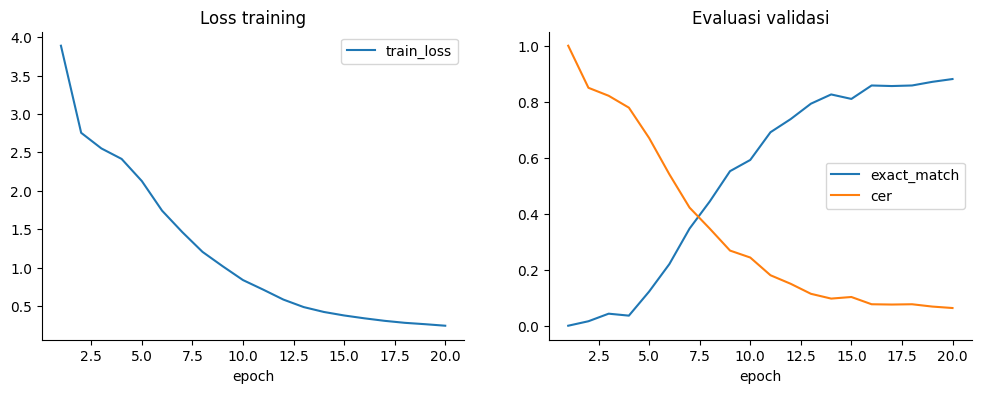

In [ ]:
# @title Training CTC dan simpan checkpoint validasi terbaik
history=[];best=-1;started=time.perf_counter()
for epoch in range(CONFIG['epochs']):
    train_ds.epoch=epoch;model.train();running=0
    for images,targets,lengths,_ in train_loader:
        images,targets=images.to(DEVICE),targets.to(DEVICE)
        optimizer.zero_grad()
        logits=model(images)
        log_probs=logits.log_softmax(-1).transpose(0,1)
        input_lengths=torch.full((len(images),),logits.shape[1],dtype=torch.long)
        loss=criterion(log_probs,targets,input_lengths,lengths)
        loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.0);optimizer.step()
        running+=loss.item()*len(images)
    val_metrics,_=evaluate_numbers(model,val_loader)
    history.append({'epoch':epoch+1,'train_loss':running/len(train_ds),**val_metrics})
    print(history[-1])
    if val_metrics['exact_match']>best:
        best=val_metrics['exact_match'];torch.save(model.state_dict(),ART/'best_training.pt')
training_seconds=time.perf_counter()-started
model.load_state_dict(torch.load(ART/'best_training.pt',map_location=DEVICE,weights_only=True))
history_df=pd.DataFrame(history);history_df.to_csv(ART/'history.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4))
history_df.plot(x='epoch',y='train_loss',ax=axes[0],title='Loss training')
history_df.plot(x='epoch',y=['exact_match','cer'],ax=axes[1],title='Evaluasi validasi');plt.show()


# 5. Evaluasi

**Exact match** mengharuskan seluruh string benar. **CER** menghitung jarak
edit karakter dibagi jumlah karakter referensi. Laporan per panjang urutan
memperlihatkan apakah model hanya bagus untuk satu digit.
Evaluasi tambahan mencakup semua nilai 0–100 dan bilangan dengan digit berulang.
Semua pengujian berikut tetap sintetis dan tidak membuktikan kinerja kanvas nyata.


In [ ]:
# @title Evaluasi akhir, kelompok panjang, dan contoh kesalahan
metrics,predictions=evaluate_numbers(model,test_loader)
metrics.update(test_sequences=len(test_ds),training_seconds=training_seconds,real_canvas_evaluated=False)
display(pd.Series(metrics));display(predictions.groupby('length').agg(jumlah=('correct','size'),exact_match=('correct','mean')))
display(predictions[~predictions.correct].head(20))
predictions.to_csv(ART/'predictions.csv',index=False)
targets=[str(i) for i in range(101)]+['11','22','33','44','55','66','77','88','99','100']*5
special_ds=SyntheticNumbers(*pools['test'],len(targets),SEED+30000000,targets=targets)
special_metrics,special_results=evaluate_numbers(model,DataLoader(special_ds,batch_size=128,collate_fn=collate_numbers))
display(pd.Series(special_metrics,name='cakupan_nilai_dan_digit_berulang'))
special_results.to_csv(ART/'special_cases.csv',index=False)
save_json(ART/'metrics.json',metrics);save_json(ART/'special_metrics.json',special_metrics)


,0
exact_match,0.876
cer,0.067267
test_sequences,1000
training_seconds,328.859299
real_canvas_evaluated,False


,jumlah,exact_match
length,,
1,170,0.982353
2,772,0.862694
3,58,0.741379


,target,prediction,correct,edits,length
16,55,58,False,1,2
43,01,91,False,1,2
59,50,58,False,1,2
68,62,63,False,1,2
74,06,46,False,1,2
84,918,318,False,1,3
86,16,1,False,1,2
91,885,85,False,1,3
93,48,43,False,1,2
115,58,98,False,1,2


,cakupan_nilai_dan_digit_berulang
exact_match,0.874172
cer,0.067114


# 6. Deployment dan Penyimpanan Model

Browser menyediakan citra grayscale dengan **tinta putih pada latar hitam**.
Jika kanvas memakai tinta hitam di latar putih, balik polaritas sebelum crop.
Transparansi harus dikompositkan pada latar yang benar. Input kosong ditolak
sebelum inferensi. Model menerima tensor `[batch,1,32,96]`; keluaran berupa
logits `[batch,24,11]`, lalu decoder CTC mengubahnya menjadi string.

Penolakan PoC: input kosong, string kosong, lebih dari tiga digit, atau nilai
di luar 0–100. Belum ada confidence threshold OCR yang dikalibrasi untuk
scribble dan input asing; konfirmasi pengguna tetap wajib.


In [ ]:
# @title Simpan PyTorch, ONNX, decoder, dan konfigurasi preprocessing
import onnx,onnxruntime as ort,inspect
model=model.cpu().eval()
torch.save({'state_dict':model.state_dict(),'config':CONFIG},ART/'number_crnn.pt')
torch.onnx.export(model,torch.zeros(1,1,32,96),str(ART/'number_crnn.onnx'),
                  input_names=['image'],output_names=['logits'],opset_version=17,dynamo=False,
                  dynamic_axes={'image':{0:'batch'},'logits':{0:'batch'}})
onnx.checker.check_model(onnx.load(ART/'number_crnn.onnx'))
save_json(ART/'config.json',CONFIG)
save_json(ART/'preprocessing.json',{'height':32,'width':96,'channels':1,'polarity':'white_ink_black_background',
          'layout':'NCHW','normalization':'float32 / 255; crop ink bbox; aspect-preserving resize; centered padding',
          'blank_id':10,'range':[0,100],'confirmation_required':True})
(ART/'preprocessing.py').write_text('import numpy as np\nfrom PIL import Image\n\n'+inspect.getsource(preprocess_canvas))
decoder_source='''def decode_ctc_ids(ids, blank=10):
    result=[]; previous=blank
    for value in ids:
        value=int(value)
        if value!=blank and value!=previous: result.append(str(value))
        previous=value
    return ''.join(result)
'''
(ART/'decoder.py').write_text(decoder_source)


/tmp/ipykernel_680/2716624969.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model,torch.zeros(1,1,32,96),str(ART/'number_crnn.onnx'),
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:4604: UserWarning: Exporting a model to ONNX with a batch_size other than 1, with a variable length with GRU can cause an error when running the ONNX model with a different batch size. Make sure to save the model with a batch size of 1, or define the initial states (h0/c0) as inputs of the model. 
  return _generic_rnn(


233

In [ ]:
# @title Uji kesetaraan ONNX dan muat ulang model final
session=ort.InferenceSession(str(ART/'number_crnn.onnx'),providers=['CPUExecutionProvider'])
sample=torch.stack([test_ds[i][0] for i in range(4)]).numpy()
with torch.no_grad(): reference=model(torch.from_numpy(sample)).numpy()
actual=session.run(None,{'image':sample})[0]
np.testing.assert_allclose(actual,reference,rtol=1e-3,atol=1e-4)
reloaded=NumberCRNN();reloaded.load_state_dict(torch.load(ART/'number_crnn.pt',weights_only=True)['state_dict'])
with torch.no_grad(): np.testing.assert_allclose(reloaded.eval()(torch.from_numpy(sample)).numpy(),reference)
for _ in range(5):session.run(None,{'image':sample[:1]})
timings=[]
for _ in range(50):
    tick=time.perf_counter();session.run(None,{'image':sample[:1]});timings.append((time.perf_counter()-tick)*1000)
save_json(ART/'export_check.json',{'max_abs_error':float(np.abs(actual-reference).max()),
          'cpu_onnx_p50_p95_ms':np.percentile(timings,[50,95]).tolist(),'browser_benchmarked':False})
print('Parity lulus. Prediksi contoh:',decode_ctc(torch.from_numpy(actual)))


Parity lulus. Prediksi contoh: ['70', '4', '0', '27']


## Kesimpulan dan batas interpretasi

Model ini belajar membaca bilangan sintetis dari digit publik. Keberhasilan
sintesis dan ekspor harus dipisahkan dari keberhasilan input touchscreen nyata.
Setelah PoC, prioritasnya adalah mengukur domain shift pada kanvas, input
motorik beragam, dan false acceptance terhadap scribble.

**Referensi:** [MNIST](https://www.tensorflow.org/datasets/catalog/mnist),
[EMNIST](https://www.nist.gov/itl/products-and-services/emnist-dataset),
[pola CNN/RNN/CTC](https://keras.io/examples/vision/captcha_ocr/),
[CTCLoss PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.CTCLoss.html).


In [ ]:
# @title Paket model dan laporan akhir
import shutil
save_environment(ART);display(index_artifacts(ART))
archive=shutil.make_archive(str(ART.parent/'tulisan_tangan'),'zip',ART)
from IPython.display import FileLink
display(FileLink(archive));print('Artefak:',archive)


,file,bytes,sha256
0,best_training.pt,757027,5516cfd89cddcd8c2959d03010675d25befa9f1dc9cab5...
1,config.json,216,3d711fff8c019439d9ff5eb94f591079d8e5f42056c053...
2,decoder.py,233,b12a5ded6f2c92f360309a8eb10ccdbe5ab36231e16dc0...
3,environment.json,244,ea9e3781e878b59bdae77e463753e83aa49175d9e1f55e...
4,export_check.json,154,547fd5901792f9cf8df47c03b1f00b4b58027398013a0a...
5,history.csv,955,d22f153272bcb00567815f3a3765af9ac224ef7bcc74b2...
6,metrics.json,154,9e452ea2958c2a3bbe0bc1feb8df66ea53ec077f5de516...
7,number_crnn.onnx,755813,37c9acea621230a2de9b077e85ef12aa736ad862c12cb4...
8,number_crnn.pt,758475,433d04e368d6cc91703271857ea32cd11587cb2b2b8f11...
9,predictions.csv,14902,24ad12f5ee23d0dc38c2a86390a4eac26543c917c301d5...


/content/hitungin/artifacts/tulisan_tangan.zip

Artefak: /content/hitungin/artifacts/tulisan_tangan.zip
